we are going to implement Grover’s Search Algorithm using Qiskit. The goal is to search a small unsorted space, mark one target state, amplify its probability, and then confirm the result through simulation and visualisation.

In [2]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

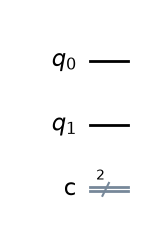

In [3]:
grover_circuit = QuantumCircuit(2, 2)

grover_circuit.draw("mpl")

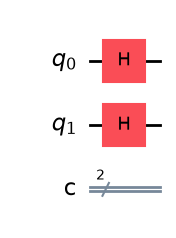

In [4]:
grover_circuit.h([0, 1])

grover_circuit.draw("mpl")

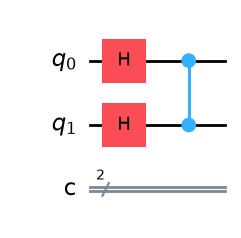

In [5]:
grover_circuit.cz(0, 1)

grover_circuit.draw("mpl")

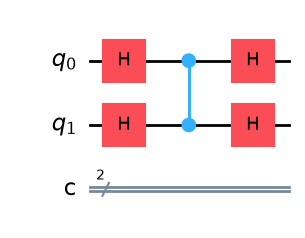

In [6]:
grover_circuit.h([0, 1])

grover_circuit.draw("mpl")

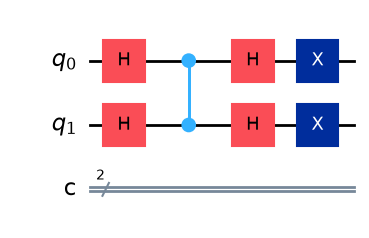

In [7]:
grover_circuit.x([0, 1])

grover_circuit.draw("mpl")

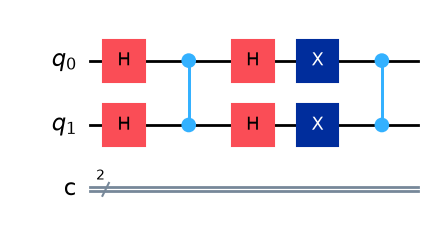

In [8]:
grover_circuit.cz(0, 1)

grover_circuit.draw("mpl")

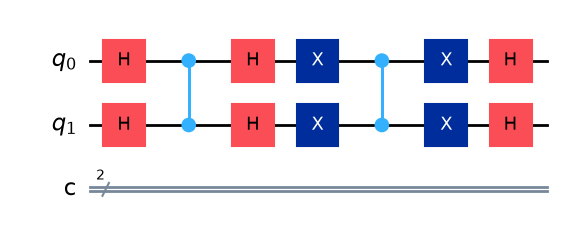

In [9]:
grover_circuit.x([0, 1])
grover_circuit.h([0, 1])

grover_circuit.draw("mpl")

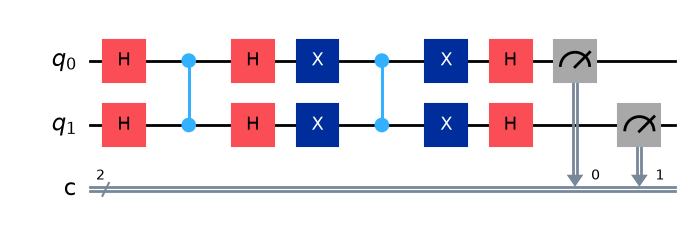

In [10]:
grover_circuit.measure([0, 1], [0, 1])

grover_circuit.draw("mpl")

In [11]:
simulator = AerSimulator()

In [12]:
result = simulator.run(
    grover_circuit,
    shots=1000
).result()

counts = result.get_counts()

print(counts)

{'11': 1000}


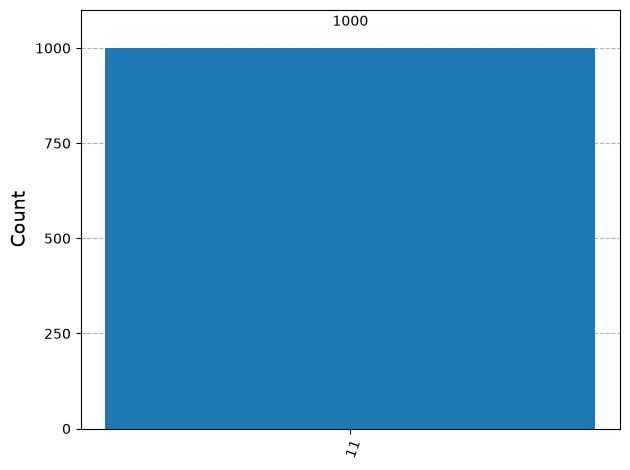

In [13]:
plot_histogram(counts)

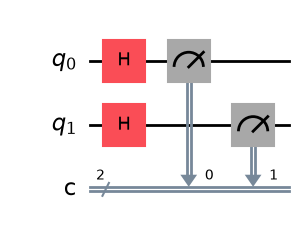

In [14]:
baseline_circuit = QuantumCircuit(2, 2)

baseline_circuit.h([0, 1])

baseline_circuit.measure([0, 1], [0, 1])

baseline_circuit.draw("mpl")

In [15]:
baseline_result = simulator.run(
    baseline_circuit,
    shots=1000
).result()

baseline_counts = baseline_result.get_counts()

print(baseline_counts)

{'11': 243, '01': 273, '10': 247, '00': 237}


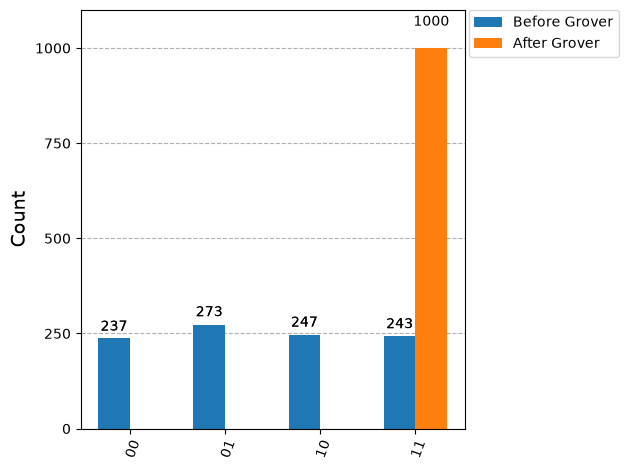

In [16]:
plot_histogram(
    [baseline_counts, counts],
    legend=["Before Grover", "After Grover"]
)

In [17]:
marked_state = max(counts, key=counts.get)

print(f"Grover search result: {marked_state}")

Grover search result: 11
